In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import nltk
import streamlit
import joblib


**Load the dataset**

In [3]:
# Import pandas

import pandas as pd

# Load dataset

file_path = r"E:\Innomatics\ML_Innomatics\Naive_Bayes_Sentiment_Analysis\Reviews_data.csv"
df = pd.read_csv(file_path)

# Display first 10 records

df.head(10)

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1
5,Now I am getting angry and I want my damn pho.,0
6,Honeslty it didn't taste THAT fresh.),0
7,The potatoes were like rubber and you could te...,0
8,The fries were great too.,1
9,A great touch.,1


**Check dataset dimensions**

In [4]:
# Check number of rows and columns

print("Dataset Shape:", df.shape)


Dataset Shape: (1000, 2)


In [5]:
# Display column names

print("Column Names:")
print(df.columns.tolist())

Column Names:
['Review', 'Liked']


In [6]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Review  1000 non-null   str  
 1   Liked   1000 non-null   int64
dtypes: int64(1), str(1)
memory usage: 72.7 KB


In [7]:
# Missing values

print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Review    0
Liked     0
dtype: int64


In [8]:
# Class distribution

print("\nClass Distribution:")
print(df["Liked"].value_counts())


Class Distribution:
Liked
1    500
0    500
Name: count, dtype: int64


In [9]:
# Class distribution in percentage

print("\nClass Percentage:")
print(df["Liked"].value_counts(normalize=True) * 100)


Class Percentage:
Liked
1    50.0
0    50.0
Name: proportion, dtype: float64


**Visualize the class distribution**

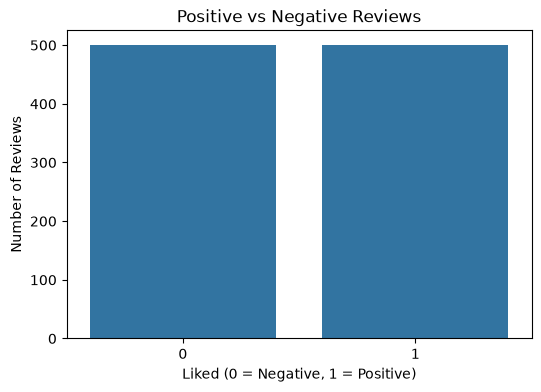

In [10]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Liked")

plt.title("Positive vs Negative Reviews")
plt.xlabel("Liked (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")

plt.show()

**Analyze review text length distribution**

1. Calculate the length of each review

In [11]:
# Calculate the number of characters in each review

df["Review_Length"] = df["Review"].apply(len)

# Display first 10 records

df[["Review", "Review_Length"]].head(10)

,Review,Review_Length
0,Wow... Loved this place.,24
1,Crust is not good.,18
2,Not tasty and the texture was just nasty.,41
3,Stopped by during the late May bank holiday of...,87
4,The selection on the menu was great and so wer...,59
5,Now I am getting angry and I want my damn pho.,46
6,Honeslty it didn't taste THAT fresh.),37
7,The potatoes were like rubber and you could te...,111
8,The fries were great too.,25
9,A great touch.,14


2. Calculate statistical information

In [12]:
# Statistical summary of review length

df["Review_Length"].describe()

count    1000.000000
mean       58.315000
std        32.360052
min        11.000000
25%        33.000000
50%        51.000000
75%        80.000000
max       149.000000
Name: Review_Length, dtype: float64

3. Visualize review length distribution

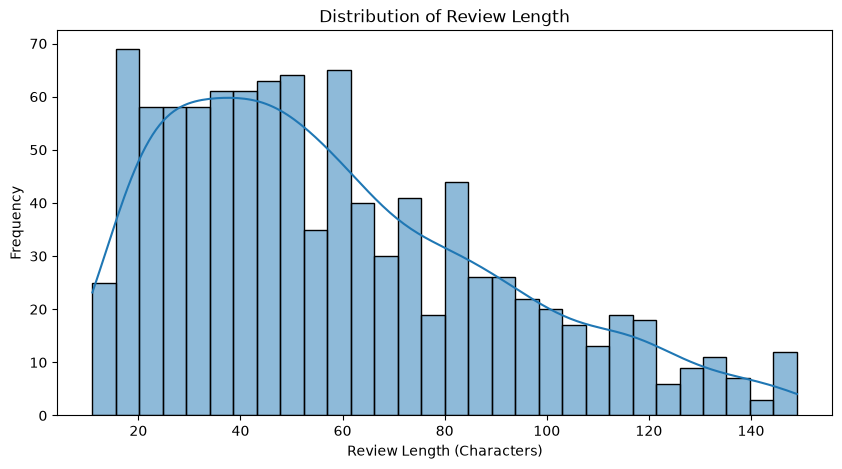

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Review_Length",
    bins=30,
    kde=True
)

plt.title("Distribution of Review Length")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Frequency")

plt.show()

**Text Cleaning and Preprocessing.**

In [14]:
import re
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:
# Function to clean text

def basic_cleaning(text):

    # Convert to lowercase
    text = text.lower()

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply cleaning to the entire review column

df["Cleaned_Review"] = df["Review"].apply(basic_cleaning)


# Display original and cleaned reviews

df[["Review", "Cleaned_Review"]].head(10)

,Review,Cleaned_Review
0,Wow... Loved this place.,wow loved this place
1,Crust is not good.,crust is not good
2,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty
3,Stopped by during the late May bank holiday of...,stopped by during the late may bank holiday of...
4,The selection on the menu was great and so wer...,the selection on the menu was great and so wer...
5,Now I am getting angry and I want my damn pho.,now i am getting angry and i want my damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty it didn t taste that fresh
7,The potatoes were like rubber and you could te...,the potatoes were like rubber and you could te...
8,The fries were great too.,the fries were great too
9,A great touch.,a great touch


In [16]:
# Check first 10 cleaned reviews

for i in range(10):

    print("Original Review:", df["Review"].iloc[i])

    print("Cleaned Review:", df["Cleaned_Review"].iloc[i])

    print("-" * 60)

Original Review: Wow... Loved this place.
Cleaned Review: wow loved this place
------------------------------------------------------------
Original Review: Crust is not good.
Cleaned Review: crust is not good
------------------------------------------------------------
Original Review: Not tasty and the texture was just nasty.
Cleaned Review: not tasty and the texture was just nasty
------------------------------------------------------------
Original Review: Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.
Cleaned Review: stopped by during the late may bank holiday off rick steve recommendation and loved it
------------------------------------------------------------
Original Review: The selection on the menu was great and so were the prices.
Cleaned Review: the selection on the menu was great and so were the prices
------------------------------------------------------------
Original Review: Now I am getting angry and I want my damn pho.
Cleane

In [17]:
# Check missing values

print("Missing values in cleaned reviews:")
print(df["Cleaned_Review"].isnull().sum())

# Check data types

print("\nData type:")
print(df["Cleaned_Review"].dtype)

# Display dataset shape

print("\nDataset Shape:", df.shape)

Missing values in cleaned reviews:
0

Data type:
str

Dataset Shape: (1000, 4)


Remove stopwords

In [25]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Convert stopwords into a set

stop_words = set(ENGLISH_STOP_WORDS)

print("Total Stopwords:", len(stop_words))

Total Stopwords: 318


In [26]:
# Important negative words to preserve

negative_words = {
    "no",
    "not",
    "nor",
    "never",
    "neither",
    "none",
    "nobody",
    "nothing",
    "nowhere",
    "cannot"
}

# Remove negative words from stopwords

stop_words = stop_words - negative_words

print("Updated Stopwords:", len(stop_words))

# Verify negative words

for word in negative_words:
    print(word, "Preserved:", word not in stop_words)

Updated Stopwords: 308
no Preserved: True
not Preserved: True
neither Preserved: True
never Preserved: True
none Preserved: True
nobody Preserved: True
nor Preserved: True
nowhere Preserved: True
nothing Preserved: True
cannot Preserved: True


In [27]:
# Function to remove stopwords

def remove_stopwords(text):

    # Split sentence into words
    words = text.split()

    # Remove stopwords but preserve negative words
    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    # Join words back into sentence
    return " ".join(filtered_words)

In [29]:
# Apply stopword removal to all reviews

df["Cleaned_Review"] = df["Cleaned_Review"].apply(remove_stopwords)

# Display original and processed reviews

display(df[["Review", "Cleaned_Review"]].head(10))

,Review,Cleaned_Review
0,Wow... Loved this place.,wow loved place
1,Crust is not good.,crust not good
2,Not tasty and the texture was just nasty.,not tasty texture just nasty
3,Stopped by during the late May bank holiday of...,stopped late bank holiday rick steve recommend...
4,The selection on the menu was great and so wer...,selection menu great prices
5,Now I am getting angry and I want my damn pho.,getting angry want damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty didn t taste fresh
7,The potatoes were like rubber and you could te...,potatoes like rubber tell ahead time kept warmer
8,The fries were great too.,fries great
9,A great touch.,great touch


In [30]:
# Sample negative reviews

test_reviews = [
    "I do not like this food",
    "The service is not good",
    "I never enjoyed this restaurant",
    "There is no taste in the food",
    "Neither the food nor the service was good"
]

# Apply basic cleaning first

for review in test_reviews:

    cleaned = basic_cleaning(review)

    result = remove_stopwords(cleaned)

    print("Original:", review)
    print("Processed:", result)
    print("-" * 60)

Original: I do not like this food
Processed: not like food
------------------------------------------------------------
Original: The service is not good
Processed: service not good
------------------------------------------------------------
Original: I never enjoyed this restaurant
Processed: never enjoyed restaurant
------------------------------------------------------------
Original: There is no taste in the food
Processed: no taste food
------------------------------------------------------------
Original: Neither the food nor the service was good
Processed: neither food nor service good
------------------------------------------------------------


Perform stemming

In [33]:
from nltk.stem import PorterStemmer

# Initialize Porter Stemmer

stemmer = PorterStemmer()

In [34]:
# Function for stemming

def apply_stemming(text):

    # Split text into individual words
    words = text.split()

    # Apply stemming to each word
    stemmed_words = [
        stemmer.stem(word) for word in words
    ]

    # Join words into a sentence
    return " ".join(stemmed_words)

In [36]:
# Apply stemming to all cleaned reviews

df["Cleaned_Review"] = df["Cleaned_Review"].apply(apply_stemming)

# Display original and processed reviews

display(df[["Review", "Cleaned_Review"]].head(10))

,Review,Cleaned_Review
0,Wow... Loved this place.,wow love place
1,Crust is not good.,crust not good
2,Not tasty and the texture was just nasty.,not tasti textur just nasti
3,Stopped by during the late May bank holiday of...,stop late bank holiday rick steve recommend love
4,The selection on the menu was great and so wer...,select menu great price
5,Now I am getting angry and I want my damn pho.,get angri want damn pho
6,Honeslty it didn't taste THAT fresh.),honeslti didn t tast fresh
7,The potatoes were like rubber and you could te...,potato like rubber tell ahead time kept warmer
8,The fries were great too.,fri great
9,A great touch.,great touch


In [38]:
# Display first 10 processed reviews

for i in range(10):

    print("Original:", df["Review"].iloc[i])

    print("Processed:", df["Cleaned_Review"].iloc[i])

    print("-" * 50)

Original: Wow... Loved this place.
Processed: wow love place
--------------------------------------------------
Original: Crust is not good.
Processed: crust not good
--------------------------------------------------
Original: Not tasty and the texture was just nasty.
Processed: not tasti textur just nasti
--------------------------------------------------
Original: Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.
Processed: stop late bank holiday rick steve recommend love
--------------------------------------------------
Original: The selection on the menu was great and so were the prices.
Processed: select menu great price
--------------------------------------------------
Original: Now I am getting angry and I want my damn pho.
Processed: get angri want damn pho
--------------------------------------------------
Original: Honeslty it didn't taste THAT fresh.)
Processed: honeslti didn t tast fresh
----------------------------------------------

Train-Test Split

In [40]:
from sklearn.model_selection import train_test_split

# Features (input reviews)
X = df["Cleaned_Review"]

# Target (sentiment labels)
y = df["Liked"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the shapes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (800,)
Testing data: (200,)
Training labels: (800,)
Testing labels: (200,)


CountVectorizer (Bag of Words)

In [41]:
from sklearn.feature_extraction.text import CountVectorizer

# Initialize CountVectorizer
bow = CountVectorizer()

# Fit and transform training data
X_train_bow = bow.fit_transform(X_train)

# Transform testing data
X_test_bow = bow.transform(X_test)

# Display shapes
print("Training data shape:", X_train_bow.shape)
print("Testing data shape:", X_test_bow.shape)

Training data shape: (800, 1312)
Testing data shape: (200, 1312)


TF-IDF Vectorizer

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer()

# Fit and transform training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

# Display shapes
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (800, 1312)
Testing data shape: (200, 1312)


In [43]:
# Display first 5 feature names
print(tfidf.get_feature_names_out()[:20])

# Display numerical representation of first 5 reviews
print(X_train_tfidf[:5].toarray())

['absolut' 'absolutley' 'accomod' 'accordingli' 'account' 'ach'
 'acknowledg' 'actual' 'ad' 'afford' 'afternoon' 'ago' 'ahead' 'airlin'
 'airport' 'ala' 'albondiga' 'allergi' 'amaz' 'ambianc']
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


Model Training – Naive Bayes Classifier

In [44]:
from sklearn.feature_extraction.text import CountVectorizer

# Initialize binary CountVectorizer
bow_binary = CountVectorizer(binary=True)

# Convert training data
X_train_binary = bow_binary.fit_transform(X_train)

# Convert testing data
X_test_binary = bow_binary.transform(X_test)

print("Training shape:", X_train_binary.shape)
print("Testing shape:", X_test_binary.shape)

Training shape: (800, 1312)
Testing shape: (200, 1312)


Train Bernoulli Naive Bayes

In [46]:
from sklearn.naive_bayes import BernoulliNB

# Initialize the model
bnb_model = BernoulliNB()

# Train the model
bnb_model.fit(X_train_binary, y_train)

print("Bernoulli Naive Bayes model trained successfully!")

Bernoulli Naive Bayes model trained successfully!


Make predictions on test data

In [47]:
# Predict sentiment for testing reviews
y_pred = bnb_model.predict(X_test_binary)

# Display actual and predicted values
print("Actual values:", y_test.values[:10])
print("Predicted values:", y_pred[:10])

Actual values: [1 0 0 0 1 1 1 1 0 0]
Predicted values: [1 0 0 1 1 1 1 0 0 0]


Calculate evaluation metrics

In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.825
Precision: 0.8037383177570093
Recall   : 0.86
F1 Score : 0.8309178743961353

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.79      0.82       100
           1       0.80      0.86      0.83       100

    accuracy                           0.82       200
   macro avg       0.83      0.82      0.82       200
weighted avg       0.83      0.82      0.82       200



Confusion Matrix

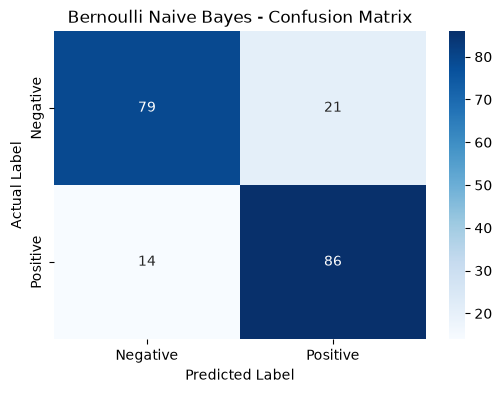

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Bernoulli Naive Bayes - Confusion Matrix")
plt.show()

Train the Multinomial Naive Bayes model

In [50]:
from sklearn.naive_bayes import MultinomialNB

# Initialize Multinomial Naive Bayes
mnb_model = MultinomialNB()

# Train using TF-IDF features
mnb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


Make predictions

In [51]:
# Predict using testing data
y_pred_mnb = mnb_model.predict(X_test_tfidf)

print("Actual values:", y_test.values[:10])
print("Predicted values:", y_pred_mnb[:10])

Actual values: [1 0 0 0 1 1 1 1 0 0]
Predicted values: [1 0 0 1 1 1 1 0 0 0]


Evaluate the model

In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_mnb = accuracy_score(y_test, y_pred_mnb)
precision_mnb = precision_score(y_test, y_pred_mnb, zero_division=0)
recall_mnb = recall_score(y_test, y_pred_mnb, zero_division=0)
f1_mnb = f1_score(y_test, y_pred_mnb, zero_division=0)

print("Multinomial Naive Bayes - TF-IDF")
print("--------------------------------")
print("Accuracy :", accuracy_mnb)
print("Precision:", precision_mnb)
print("Recall   :", recall_mnb)
print("F1 Score :", f1_mnb)


Multinomial Naive Bayes - TF-IDF
--------------------------------
Accuracy : 0.81
Precision: 0.7980769230769231
Recall   : 0.83
F1 Score : 0.8137254901960784


Compare both models

In [53]:
comparison = pd.DataFrame({
    "Model": [
        "BernoulliNB + Binary BoW",
        "MultinomialNB + TF-IDF"
    ],
    "Accuracy": [accuracy, accuracy_mnb],
    "Precision": [precision, precision_mnb],
    "Recall": [recall, recall_mnb],
    "F1 Score": [f1, f1_mnb]
})

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,BernoulliNB + Binary BoW,0.825,0.803738,0.86,0.830918
1,MultinomialNB + TF-IDF,0.810,0.798077,0.83,0.813725


Predict Sentiment for New Reviews

In [54]:
sample_reviews = [
    "The food was fantastic!",
    "Worst service ever.",
    "I really enjoyed the experience",
    "The product quality is very poor",
    "The service was not good"
]

Preprocess the new reviews

In [55]:
# Clean the sample reviews
cleaned_samples = []

for review in sample_reviews:
    cleaned = basic_cleaning(review)
    cleaned = remove_stopwords(cleaned)
    cleaned = apply_stemming(cleaned)
    cleaned_samples.append(cleaned)

print(cleaned_samples)

['food fantast', 'worst servic', 'realli enjoy experi', 'product qualiti poor', 'servic not good']


In [56]:
# Convert reviews into binary BoW features
sample_bow = bow_binary.transform(cleaned_samples)

# Predict sentiment
bnb_predictions = bnb_model.predict(sample_bow)

for review, prediction in zip(sample_reviews, bnb_predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

Review: The food was fantastic!
Predicted Sentiment: Positive
--------------------------------------------------
Review: Worst service ever.
Predicted Sentiment: Negative
--------------------------------------------------
Review: I really enjoyed the experience
Predicted Sentiment: Positive
--------------------------------------------------
Review: The product quality is very poor
Predicted Sentiment: Negative
--------------------------------------------------
Review: The service was not good
Predicted Sentiment: Negative
--------------------------------------------------


Predict using Multinomial Naive Bayes

In [57]:
# Convert reviews into TF-IDF features
sample_tfidf = tfidf.transform(cleaned_samples)

# Predict sentiment
mnb_predictions = mnb_model.predict(sample_tfidf)

for review, prediction in zip(sample_reviews, mnb_predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

Review: The food was fantastic!
Predicted Sentiment: Positive
--------------------------------------------------
Review: Worst service ever.
Predicted Sentiment: Negative
--------------------------------------------------
Review: I really enjoyed the experience
Predicted Sentiment: Positive
--------------------------------------------------
Review: The product quality is very poor
Predicted Sentiment: Negative
--------------------------------------------------
Review: The service was not good
Predicted Sentiment: Negative
--------------------------------------------------


In [58]:
import joblib
import os

# Create a folder to store trained models
os.makedirs("models", exist_ok=True)

# Save all trained models and vectorizers
joblib.dump(bnb_model, "models/bernoulli_model.pkl")
joblib.dump(bow_binary, "models/bow_vectorizer.pkl")

joblib.dump(mnb_model, "models/multinomial_model.pkl")
joblib.dump(tfidf, "models/tfidf_vectorizer.pkl")

print("All models and vectorizers saved successfully!")

All models and vectorizers saved successfully!


In [59]:
print("Saved model files:")

for file in os.listdir("models"):
    print(file)

Saved model files:
bernoulli_model.pkl
bow_vectorizer.pkl
multinomial_model.pkl
tfidf_vectorizer.pkl
